## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
%matplotlib inline
pd.set_option('display.max_columns', None)

In [3]:
df = pd.read_csv("../../../Day1/amz_uk_price_prediction_dataset.csv")

In [ ]:
df.head(10)

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [4]:
# Check if the data set has NaN values
df.isna().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*

In [117]:
crosstab = pd.crosstab(df.category, df.isBestSeller)
crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [130]:
# Create the percent table and round the values to have clearer view
crosstab_percent = pd.crosstab(df.category, df.isBestSeller, normalize = "index").round(2)
crosstab_percent

isBestSeller,False,True
category,,
3D Printers,1.00,0.00
3D Printing & Scanning,1.00,0.00
Abrasive & Finishing Products,0.98,0.02
Action Cameras,1.00,0.00
Adapters,0.99,0.01
...,...,...
Wind Instruments,0.97,0.03
Window Treatments,0.98,0.02
Women,0.99,0.01


In [10]:
# Concatenate the crosstables together to show counts and percent together
crosstab_result = pd.concat([crosstab,crosstab_percent], axis=1)

# The concatenation duplicates the columns true and False, I can't then use the sort on those columns.
# I choose to join instead to avoid this problem, I also add the suffix _percent to differentiate the columns
crosstab_result = crosstab.join(crosstab_percent, rsuffix="_percent")
crosstab_result

isBestSeller,False,True,False_percent,True_percent
category,,,,
3D Printers,247,1,1.00,0.00
3D Printing & Scanning,4065,2,1.00,0.00
Abrasive & Finishing Products,245,5,0.98,0.02
Action Cameras,1696,1,1.00,0.00
Adapters,251,3,0.99,0.01
...,...,...,...,...
Wind Instruments,243,7,0.97,0.03
Window Treatments,234,5,0.98,0.02
Women,17559,213,0.99,0.01


In [113]:
# Sort by descending order the Best Sellers as percentage with 'True_percent' column.
crosstab_result.sort_values(by = 'True_percent', ascending = False).head(10)

isBestSeller,False,True,False_percent,True_percent
category,,,,
Smart Home Security & Lighting,98,6,0.94,0.06
Health & Personal Care,9017,552,0.94,0.06
Grocery,9008,556,0.94,0.06
Power & Hand Tools,8353,306,0.96,0.04
Mobile Phone Accessories,248,11,0.96,0.04
Home Brewing & Wine Making,239,7,0.97,0.03
Wind Instruments,243,7,0.97,0.03
"Billiard, Snooker & Pool",241,8,0.97,0.03
Bakeware,233,6,0.97,0.03


The display of the ratios shows that the categories "Smart Home Security & Lighting", "Health & Personal Care" and "Grocery" have the highest ratios with 6% of the products in those categories being Best Sellers.

2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [14]:
from scipy.stats import chi2_contingency

In [13]:
_, chi2_pvalue, _, _ = chi2_contingency(crosstab)
print(chi2_pvalue)

0.0


The chi-square value is 0 indicating that Best Sellers and product category are independent.

In [15]:
from scipy.stats.contingency import association

In [16]:
association(crosstab, method ='cramer')

0.1222829439760564

The Cramér's V result is 0.12 showcasing a weak (close to 0) strength of association between the product category and if it is a Best Seller.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

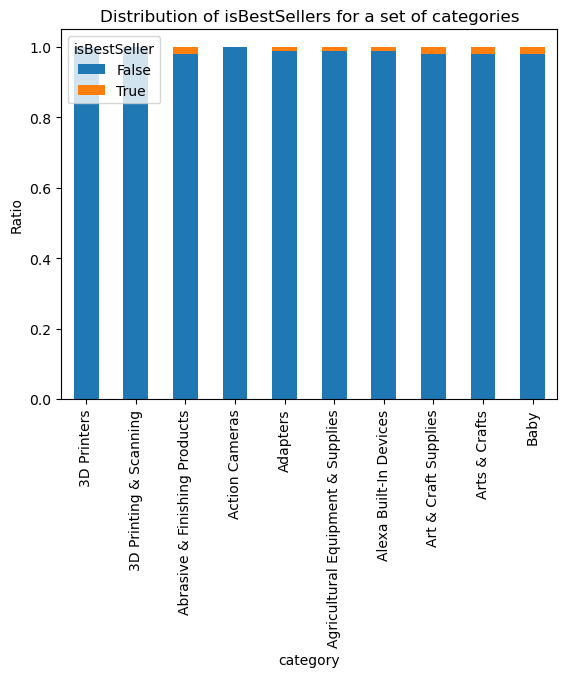

In [141]:
crosstab_percent.head(10).plot(kind='bar',stacked=True)
plt.xticks(rotation=90)
plt.ylabel("Ratio")
plt.title("Distribution of isBestSellers for a set of categories")
plt.show()

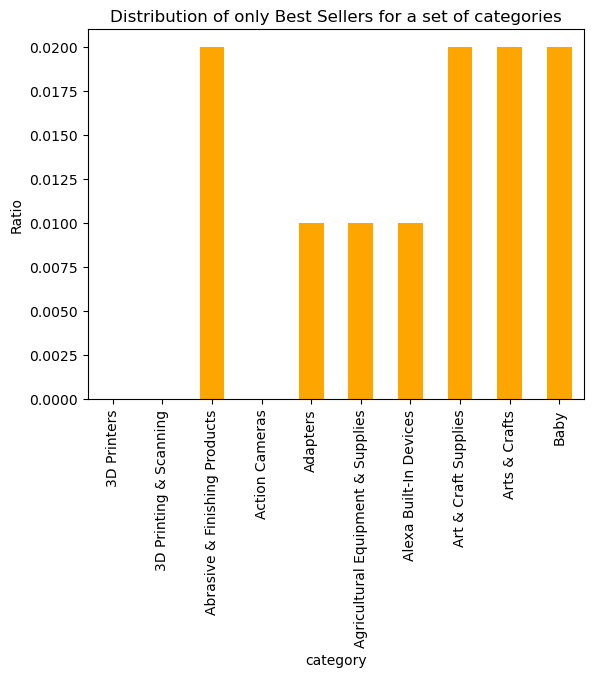

In [139]:
# We can also only show only the Best Sellers ratios (isBestSeller = True)
crosstab_percent[True].head(10).plot(kind='bar',stacked=True, color='orange')
plt.xticks(rotation=90)
plt.ylabel("Ratio")
plt.title("Distribution of only Best Sellers for a set of categories")
plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

In [71]:
def outlier_slayer(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    
    # Modify the Tukey's method to return the data without the outliers
    # cleaned_data = data[(data >= lower_bound) & (data <= upper_bound)]

    return outliers

In [ ]:
df.price.describe().round(2)

count    2443651.00
mean          89.24
std          345.61
min            0.00
25%            9.99
50%           19.09
75%           45.99
max       100000.00
Name: price, dtype: float64

In [83]:
outliers = outlier_slayer(df.price)
# Drop the outliers from the DataFrame
df2 = df.drop(index=outliers.index)

# Check that the outliers are gone
df2.price.describe().round(2)

count    2115963.00
mean          23.41
std           20.51
min            0.00
25%            9.13
50%           15.99
75%           29.99
max           99.99
Name: price, dtype: float64

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

In [ ]:
# Collect the top 20 categories indexes (names)
short_categories = df2.category.value_counts().sort_values(ascending = False).head(20).index
short_categories
# Reduce the dataframe to only have the top 20 categories
price_short_categories = df2[df2['category'].isin(short_categories)]
price_short_categories

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
19513,21072,B09477KHQ3,"Personalised Birthday Print Gift ""THE YEAR YOU...",4.5,763,7.99,False,900,Handmade Home & Kitchen Products
19514,21073,B0BSRFQYG8,Wax Melts 4 Bars | Build Your Own Box (Choose ...,3.9,117,6.49,True,800,Handmade Home & Kitchen Products
19515,21074,B09N9GVHV9,"Personalised Birthday Print Gift ""ON THE DAY/Y...",4.6,1155,8.99,True,600,Handmade Home & Kitchen Products
19516,21075,B0BRYGV7PQ,Fresh Wax Melts - Laundry Type Wax Melts - Str...,4.5,56,4.99,True,500,Handmade Home & Kitchen Products
19517,21076,B0B1JHB28R,Manta Makes Work Leaving Gifts | I Used to Wor...,4.7,261,9.95,True,400,Handmade Home & Kitchen Products
...,...,...,...,...,...,...,...,...,...
2429088,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2429089,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2429090,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2437153,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


C:\Users\vince\AppData\Local\Temp\ipykernel_21724\3303042596.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data = price_short_categories, x='category', y='price', palette="coolwarm")


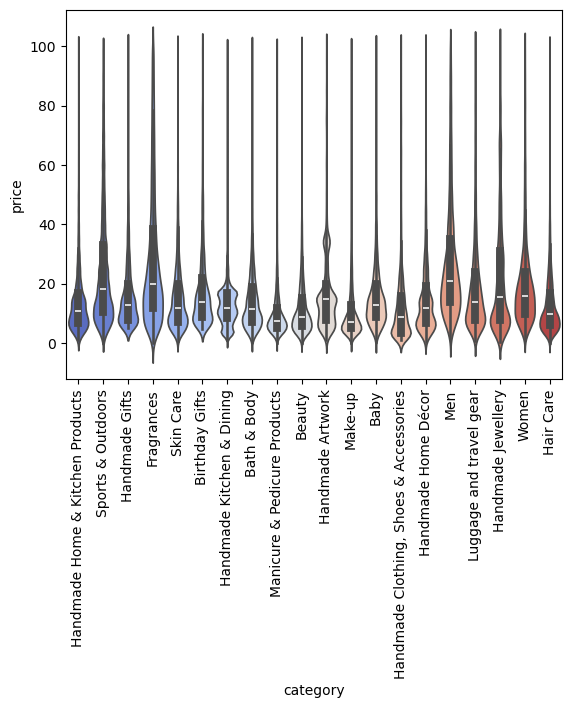

In [82]:
sns.violinplot(data = price_short_categories, x='category', y='price', palette="coolwarm")
plt.xticks(rotation = 90)
plt.show()

In [86]:
median_price = df2.groupby('category')['price'].median()
median_price.sort_values(ascending = False)

category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

The highest median price appears in the Desktop PCs category.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

In [ ]:
top_10 = df2.category.value_counts().sort_values(ascending = False).head(10).index
top_10
# Reduce the dataFrame size
top_10_df = df2[df2['category'].isin(top_10)]

In [89]:
average_price_top10 = top_10_df.groupby('category')['price'].mean()
average_price_top10

category
Bath & Body                               14.678683
Beauty                                    12.523480
Birthday Gifts                            18.600195
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Handmade Gifts                            17.395112
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Skin Care                                 15.654722
Sports & Outdoors                         25.172065
Name: price, dtype: float64

C:\Users\vince\AppData\Local\Temp\ipykernel_21724\4054266505.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(average_price_top10, palette="coolwarm")


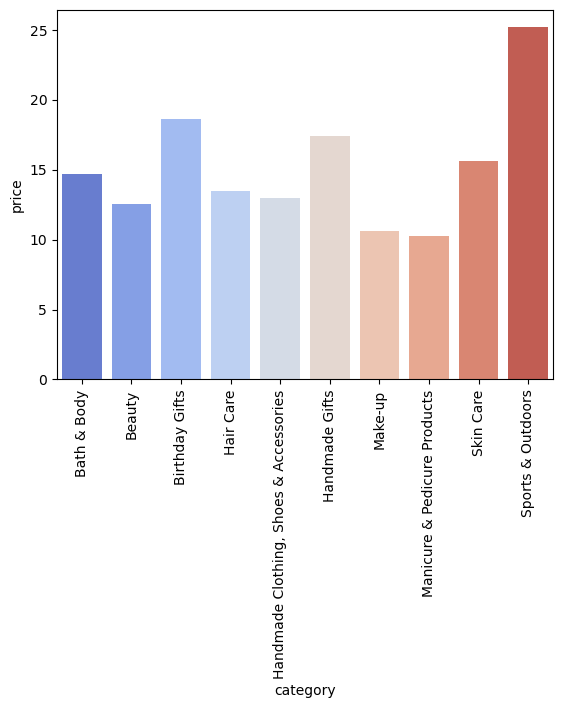

In [91]:
sns.barplot(average_price_top10, palette="coolwarm")
plt.xticks(rotation = 90)
plt.show()

In [93]:
average_price = df2.groupby('category')['price'].mean().round(2)
average_price.sort_values(ascending = False)

category
Motherboards             68.77
Boxing Shoes             67.42
Desktop PCs              66.92
Tablets                  66.55
Graphics Cards           65.10
                         ...  
Bedding Accessories       8.84
Adapters                  8.75
Signs & Plaques           8.21
Arts & Crafts             8.01
Office Paper Products     6.88
Name: price, Length: 296, dtype: float64

Tehe category showing the highest avergae price is the Motherboards category with prices averaging at 68.77 £.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [96]:
top_10_df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

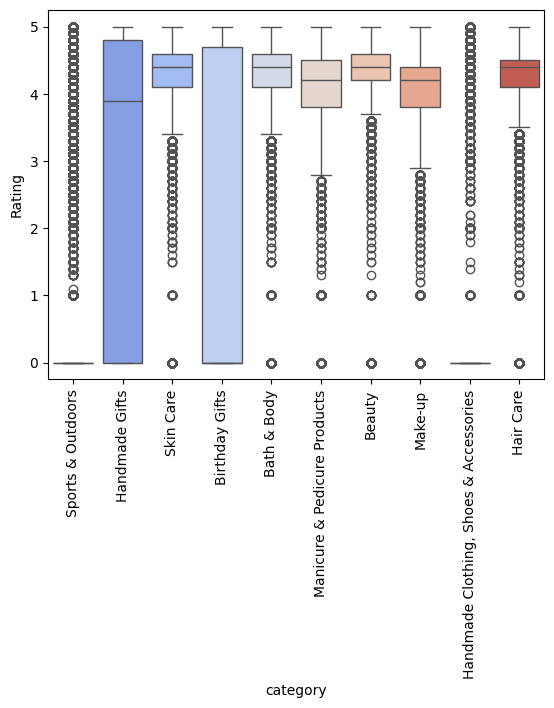

In [99]:
sns.boxplot(data=top_10_df,x="category", y="stars", hue="category", palette="coolwarm")    # top of the box = Q75 and bottom = Q25
plt.xticks(rotation = 90)
plt.ylabel("Rating")
plt.show()

In [100]:
median_stars = df2.groupby('category')['stars'].median()
median_stars.sort_values(ascending = False)

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
                               ... 
Hockey Shoes                    0.0
Hi-Fi Receivers & Separates     0.0
Handmade Kitchen & Dining       0.0
Handmade Jewellery              0.0
eBook Readers & Accessories     0.0
Name: stars, Length: 296, dtype: float64

The category with the highest stars median is Computer Memory.

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?

In [102]:
# here I choose to analyze the cleaned data frame df2, without the outliers.

# Calculate Pearson correlation coefficient (r)
pear = round(df2.price.corr(df2.stars, method='pearson'),2)
spear = round(df2.price.corr(df2.stars, method='spearman'),2)
print(f"The Pearson coeff is: {pear}")
print(f"The Spearman coeff is: {spear}")

The Pearson coeff is: -0.08
The Spearman coeff is: -0.07


Both coefficients are slightly negative, this indicate that the relation between ratings and price is weak (close to 0) with a very low tendancy to negative slope (when one increases the other slightly decreases).

2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 


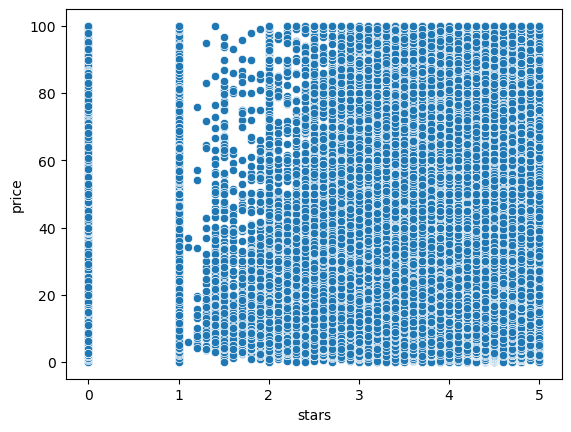

In [105]:
sns.scatterplot(data=df2, x='stars', y="price")
plt.show()

We observe vertical lines, no linear regression (ax = y) can be drown because a price can have multiple ratings and vice versa. This is supported by the correlation coefficients calculated, they also support the negligible dependency between price and ratings. 

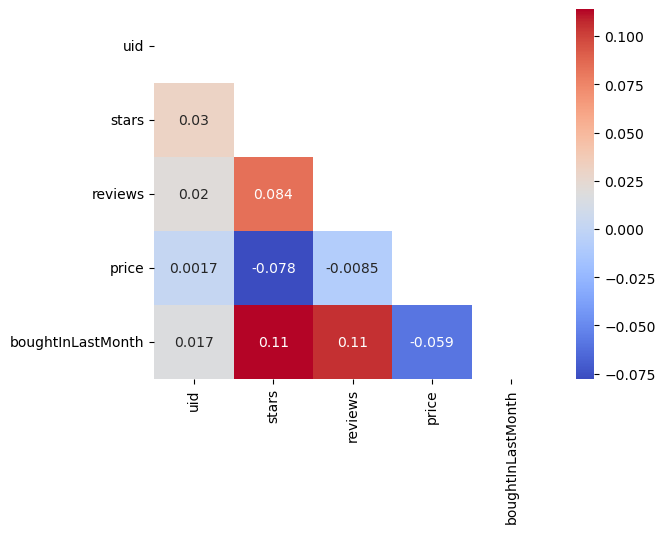

In [107]:
num = df2.select_dtypes(include = 'number')
corr_matrix = num.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask = mask, annot = True, cmap ='coolwarm')
plt.show()

Overall the values of the coefficents are low, between 0.11 and -0.078. This shows that the numerical variable have overall negligible dependencies between each other.

In [108]:
import statsmodels.api as sm

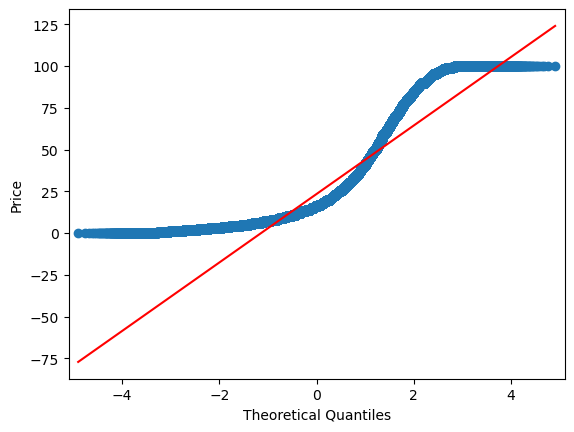

In [110]:
sm.qqplot(df2.price, line='s')
plt.ylabel('Price')
plt.show()

The QQ plot shows a strong deviation from the linear regression (in red). It shows that the prices don't follow a linear distribution. The S shape curve could be fit with another non-linear model.